# 04 - Baseline Model Training

## 1. Objective

First models for predicting **next week's dengue cases** in each district:

1. **Persistence baseline** - "next week will have the same number of cases as this week". It needs no training and sets the minimum standard: a machine-learning model is only useful if it beats it.
2. **Random Forest** - the first ensemble model. It is trained twice: once on the raw target `cases_next`, and once on the log target `target_log_next` (predictions converted back with `np.expm1`), to see which target works better.

**Evaluation:** chronological validation inside the training period (2007-2023), with **MAE** and **RMSE** in actual dengue cases. The 2024-2026 test set (`test.csv`) is **not loaded in this notebook**; it is kept for the final evaluation.

- **MAE** (mean absolute error) - the average size of the error in cases per district-week. Easy to interpret.
- **RMSE** (root mean squared error) - squares the errors before averaging, so large misses (e.g. an underestimated outbreak) count much more.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

DATA_DIR = Path("../dataset")
TRAIN_PATH = DATA_DIR / "processed" / "train.csv"

FEATURES = [
    "current_week_cases",
    "previous_week_cases",
    "previous_2_weeks_cases",
    "previous_3_weeks_cases",
    "seasonal_cases_previous_52_weeks",
    "moving_average_4_weeks",
    "moving_average_8_weeks",
    "weekly_case_change",
    "seasonal_week_sin",
    "seasonal_week_cos",
    "district_code",
]

VALIDATION_YEARS = [2019, 2020, 2021, 2022, 2023]
RANDOM_STATE = 42

# chart colours: actual values in dark ink, models in two fixed hues
INK, BLUE, ORANGE, GRID = "#0b0b0b", "#2a78d6", "#eb6834", "#e4e3df"

## 2. Load the training data

Only `train.csv` is loaded. Every target week in it is in 2023 or earlier.

In [2]:
train = pd.read_csv(TRAIN_PATH, parse_dates=["start_date", "target_date"])

assert train["target_date"].max() <= pd.Timestamp("2023-12-31")
assert train[FEATURES + ["cases_next", "target_log_next"]].notna().all().all()

print(train.shape)
print("target weeks:", train["target_date"].min().date(), "to", train["target_date"].max().date())

(21736, 22)
target weeks: 2007-12-29 to 2023-12-30


## 3. Chronological validation folds

A random train/validation split would let the model learn from weeks that come *after* the weeks it is tested on, which is not possible in real forecasting. Instead I use an **expanding-window** scheme (also called rolling-origin or walk-forward validation):

| Fold | Model trained on target weeks | Validated on target weeks |
|---|---|---|
| 1 | 2007 - 2018 | 2019 |
| 2 | 2007 - 2019 | 2020 |
| ... | ... | ... |
| 5 | 2007 - 2022 | 2023 |

Each fold only uses the past to predict the next year, like the model would be used in practice. Averaging over five years gives a more reliable estimate than a single split, because outbreak years and quiet years differ a lot.

Weeks whose **target** was estimated during cleaning (`target_imputed`) are left out of the validation scores, because they are not real observations. They stay in the training data.

In [3]:
target_year = train["target_date"].dt.year

folds = []
for year in VALIDATION_YEARS:
    fit_rows = target_year < year
    valid_rows = (target_year == year) & ~train["target_imputed"]
    folds.append((year, fit_rows, valid_rows))

pd.DataFrame([
    {
        "validation year": year,
        "training rows": fit_rows.sum(),
        "last training target": train.loc[fit_rows, "target_date"].max().date(),
        "validation rows": valid_rows.sum(),
    }
    for year, fit_rows, valid_rows in folds
])

,validation year,training rows,last training target,validation rows
0,2019,14950,2018-12-29,1352
1,2020,16302,2019-12-28,1352
2,2021,17654,2020-12-26,1352
3,2022,19006,2021-12-25,1352
4,2023,20384,2022-12-31,1352


## 4. Persistence baseline

The prediction for next week is simply this week's count: `predicted cases_next = current_week_cases`. There is nothing to train.

In [4]:
def score(actual, predicted):
    return {"MAE": mean_absolute_error(actual, predicted), "RMSE": root_mean_squared_error(actual, predicted)}

results = []
for year, fit_rows, valid_rows in folds:
    valid = train[valid_rows]
    results.append({"year": year, "model": "Persistence", **score(valid["cases_next"], valid["current_week_cases"])})

pd.DataFrame(results).round(2)

,year,model,MAE,RMSE
0,2019,Persistence,16.69,34.39
1,2020,Persistence,7.17,15.90
2,2021,Persistence,6.97,20.39
3,2022,Persistence,11.72,21.86
4,2023,Persistence,18.17,41.82


## 5. Random Forest

A Random Forest is an **ensemble** of decision trees. Each tree is trained on a random bootstrap sample of the rows and considers a random subset of features at each split; the forest's prediction is the average of all trees. Averaging many different trees reduces the variance of a single tree, and trees need no feature scaling.

I use mostly default settings (200 trees) - this is a baseline, tuning comes later.

Two versions are trained in every fold:
- **RF (raw target):** learns `cases_next` directly.
- **RF (log target):** learns `target_log_next`; predictions are converted back with `np.expm1` so both are scored in actual cases.

In [5]:
def make_random_forest():
    return RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE)

valid_predictions = {}  # kept for the plot in section 7

for year, fit_rows, valid_rows in folds:
    fit, valid = train[fit_rows], train[valid_rows]

    rf_raw = make_random_forest().fit(fit[FEATURES], fit["cases_next"])
    pred_raw = rf_raw.predict(valid[FEATURES])

    rf_log = make_random_forest().fit(fit[FEATURES], fit["target_log_next"])
    pred_log = np.expm1(rf_log.predict(valid[FEATURES]))

    results.append({"year": year, "model": "RF (raw target)", **score(valid["cases_next"], pred_raw)})
    results.append({"year": year, "model": "RF (log target)", **score(valid["cases_next"], pred_log)})
    valid_predictions[year] = valid.assign(pred_raw=pred_raw, pred_log=pred_log)

print("done")

done


## 6. Results

Average over the five validation years, and the change compared with the persistence baseline (negative = smaller error than persistence).

In [6]:
results = pd.DataFrame(results)
MODEL_ORDER = ["Persistence", "RF (raw target)", "RF (log target)"]

summary = results.groupby("model")[["MAE", "RMSE"]].mean().loc[MODEL_ORDER]
baseline = summary.loc["Persistence"]
summary["MAE vs persistence (%)"] = 100 * (summary["MAE"] / baseline["MAE"] - 1)
summary["RMSE vs persistence (%)"] = 100 * (summary["RMSE"] / baseline["RMSE"] - 1)
summary.round(2)

,MAE,RMSE,MAE vs persistence (%),RMSE vs persistence (%)
model,,,,
Persistence,12.15,26.87,0.00,0.00
RF (raw target),12.78,28.32,5.21,5.38
RF (log target),12.67,28.59,4.31,6.39


In [7]:
# per validation year
by_year = results.pivot(index="year", columns="model", values=["MAE", "RMSE"])
by_year.reindex(columns=MODEL_ORDER, level=1).round(2)

MAE                                        RMSE                  \
model Persistence RF (raw target) RF (log target) Persistence RF (raw target)   
year                                                                            
2019        16.69           17.90           19.75       34.39           39.81   
2020         7.17            8.19            6.89       15.90           16.46   
2021         6.97            7.56            6.87       20.39           20.55   
2022        11.72           11.49           11.06       21.86           21.01   
2023        18.17           18.75           18.78       41.82           43.76   

                       
model RF (log target)  
year                   
2019            45.07  
2020            15.17  
2021            18.58  
2022            19.94  
2023            44.19

**What the results show**

- With default settings, the Random Forest does **not** beat the persistence baseline: average MAE is about 12.7-12.8 cases vs 12.15 for persistence, and RMSE is higher too. It only wins in some years (2022 for both versions, 2020-2021 for the log version).
- All models have their largest errors in the outbreak years 2019 and 2023.
- **Raw vs log target:** the log version has a slightly lower MAE but a higher RMSE. Averaging on the log scale pulls predictions down, so it does better in quiet weeks but underestimates the biggest outbreak weeks. Neither target is clearly better yet.

This is a common outcome in short-term forecasting: next week's count is usually very close to this week's, so persistence is a strong baseline. A default Random Forest also grows very deep trees (one sample per leaf), which can fit noise in the training years.

## 7. A closer look: Colombo in 2023

Actual weekly cases in the last validation year next to the persistence baseline and the better Random Forest version, for the district with the most cases.

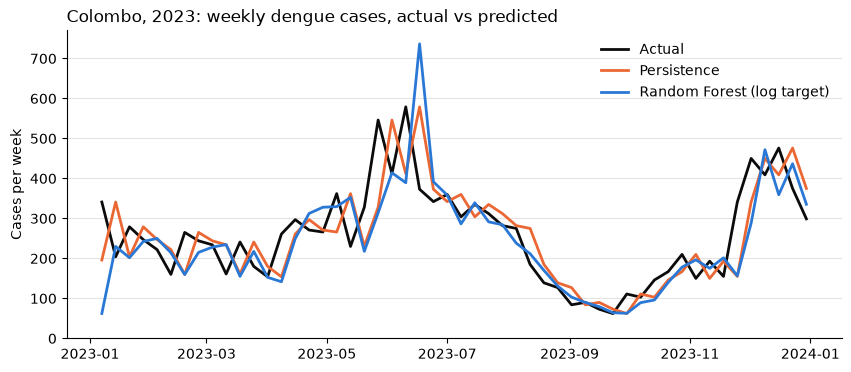

In [8]:
BEST_RF = "pred_raw" if summary.loc["RF (raw target)", "MAE"] <= summary.loc["RF (log target)", "MAE"] else "pred_log"
best_label = "Random Forest (raw target)" if BEST_RF == "pred_raw" else "Random Forest (log target)"

colombo = valid_predictions[2023].query("district == 'Colombo'").set_index("target_date").sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(colombo.index, colombo["cases_next"], color=INK, linewidth=2, label="Actual")
ax.plot(colombo.index, colombo["current_week_cases"], color=ORANGE, linewidth=2, label="Persistence")
ax.plot(colombo.index, colombo[BEST_RF], color=BLUE, linewidth=2, label=best_label)

ax.set_title("Colombo, 2023: weekly dengue cases, actual vs predicted", loc="left")
ax.set_ylabel("Cases per week")
ax.set_ylim(bottom=0)
ax.grid(axis="y", color=GRID)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

Both the baseline and the Random Forest mostly follow the actual curve **about one week late**: they react to a rise or fall after it has happened instead of anticipating it. The forest also overshoots some peaks, which is where its error becomes larger than the baseline's.

## 8. Feature importance

Impurity-based importance from the raw-target Random Forest of the last fold (trained on 2007-2022). It shows how much each feature was used to reduce the error. It is a rough guide only: it tends to favour features with many distinct values, and correlated features (the lags and moving averages) share importance between them.

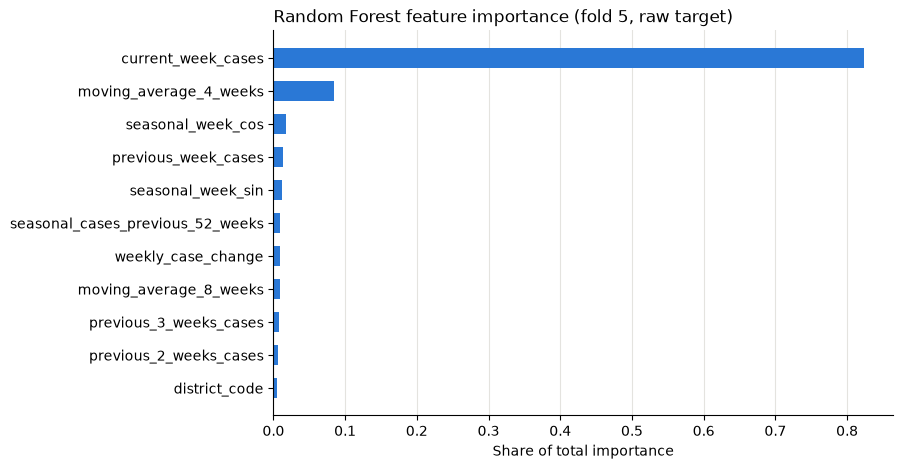

current_week_cases                  0.823
moving_average_4_weeks              0.085
seasonal_week_cos                   0.018
previous_week_cases                 0.014
seasonal_week_sin                   0.012
seasonal_cases_previous_52_weeks    0.010
weekly_case_change                  0.010
moving_average_8_weeks              0.009
previous_3_weeks_cases              0.008
previous_2_weeks_cases              0.007
district_code                       0.005
dtype: float64

In [9]:
importance = pd.Series(rf_raw.feature_importances_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.set_title("Random Forest feature importance (fold 5, raw target)", loc="left")
ax.set_xlabel("Share of total importance")
ax.set_axisbelow(True)
ax.grid(axis="x", color=GRID)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

importance.sort_values(ascending=False).round(3)

`current_week_cases` dominates (about 0.82 of the total), followed by the 4-week moving average. The forest has essentially learned the persistence rule plus small adjustments, which explains why its scores are so close to the baseline. Season, longer lags and the district code contribute little on their own.

## 9. Summary

| Model | Mean MAE (cases) | Mean RMSE (cases) |
|---|---|---|
| Persistence baseline | 12.15 | 26.87 |
| Random Forest, raw target | 12.78 | 28.32 |
| Random Forest, log target | 12.67 | 28.59 |

(Expanding-window validation, target years 2019-2023; the test set was not used.)

- The persistence baseline is hard to beat for one-week-ahead forecasts, and a default Random Forest does not beat it yet.
- The forest relies almost entirely on the current week's cases.
- The log target does not give a clear advantage over raw counts.

**Next steps**
1. Tune the Random Forest on the same validation folds (e.g. `min_samples_leaf`, `max_features`) to reduce overfitting.
2. Try predicting the *change* from the current week (`cases_next - current_week_cases`) instead of the level, so the model focuses on what persistence cannot capture.
3. Train the gradient-boosting ensembles (XGBoost, LightGBM) and the risk-level classifier with the same validation scheme.
4. Evaluate the final chosen models on the 2024-2026 test set once, at the end.